# A6v2. Оценка показателей QoS для сервисов eMBB, URLLC и mMTC в сети 5G

**Среда:** Python + Google Colab  
**Продолжительность:** 2 часа  
**Variant:** `VARIANT = 1..15`

A6v2 различает локальный queueing SLA и семантику 3GPP 5QI: PDB является бюджетом задержки, а PER задаёт верхнюю границу non-congestion потерь канального уровня; в модели radio PER=0, а queue/deadline losses учитываются отдельно.

## 1. Функции модели

In [1]:
import matplotlib.pyplot as plt

from collections import deque
import math
import numpy as np
import pandas as pd

SERVICES = ('eMBB', 'URLLC', 'mMTC')

# Synthetic teaching profiles; NOT one-to-one mappings to standardized 5QI values.
SERVICE_PROFILES = {
    'eMBB': dict(packet_size_bytes=1200, per_endpoint_rate_pps=220.0,
                 local_delay_target_ms=100.0, reliability_target=0.99,
                 buffer_limit_packets=1200),
    'URLLC': dict(packet_size_bytes=160, per_endpoint_rate_pps=220.0,
                  local_delay_target_ms=10.0, reliability_target=0.999,
                  buffer_limit_packets=500),
    'mMTC': dict(packet_size_bytes=100, per_endpoint_rate_pps=4.0,
                 local_delay_target_ms=200.0, reliability_target=0.99,
                 buffer_limit_packets=4000),
}

VARIANTS = [
    dict(variant=1,  n_embb=4, n_urllc=12, n_mmtc=100, capacity_mbps=12.0, load_scale=1.00, w_embb=3.0, w_urllc=6.0, w_mmtc=2.0, duration_ms=5000, seed=501),
    dict(variant=2,  n_embb=3, n_urllc=10, n_mmtc=80,  capacity_mbps=8.5,  load_scale=1.00, w_embb=3.0, w_urllc=5.0, w_mmtc=2.0, duration_ms=5000, seed=502),
    dict(variant=3,  n_embb=5, n_urllc=8,  n_mmtc=120, capacity_mbps=11.5, load_scale=1.05, w_embb=4.0, w_urllc=6.0, w_mmtc=2.0, duration_ms=5000, seed=503),
    dict(variant=4,  n_embb=4, n_urllc=16, n_mmtc=60,  capacity_mbps=10.0, load_scale=0.95, w_embb=3.0, w_urllc=7.0, w_mmtc=2.0, duration_ms=5000, seed=504),
    dict(variant=5,  n_embb=6, n_urllc=10, n_mmtc=150, capacity_mbps=13.5, load_scale=1.00, w_embb=4.0, w_urllc=6.0, w_mmtc=2.5, duration_ms=5000, seed=505),
    dict(variant=6,  n_embb=3, n_urllc=14, n_mmtc=180, capacity_mbps=9.0,  load_scale=1.10, w_embb=3.0, w_urllc=7.0, w_mmtc=3.0, duration_ms=5000, seed=506),
    dict(variant=7,  n_embb=5, n_urllc=18, n_mmtc=90,  capacity_mbps=12.0, load_scale=1.00, w_embb=3.5, w_urllc=8.0, w_mmtc=2.0, duration_ms=5000, seed=507),
    dict(variant=8,  n_embb=2, n_urllc=8,  n_mmtc=250, capacity_mbps=7.5,  load_scale=1.15, w_embb=3.0, w_urllc=5.0, w_mmtc=3.5, duration_ms=5000, seed=508),
    dict(variant=9,  n_embb=7, n_urllc=10, n_mmtc=70,  capacity_mbps=15.0, load_scale=0.95, w_embb=5.0, w_urllc=6.0, w_mmtc=2.0, duration_ms=5000, seed=509),
    dict(variant=10, n_embb=4, n_urllc=20, n_mmtc=200, capacity_mbps=11.0, load_scale=1.05, w_embb=3.0, w_urllc=8.0, w_mmtc=3.0, duration_ms=5000, seed=510),
    dict(variant=11, n_embb=6, n_urllc=6,  n_mmtc=100, capacity_mbps=13.0, load_scale=1.10, w_embb=5.0, w_urllc=5.0, w_mmtc=2.0, duration_ms=5000, seed=511),
    dict(variant=12, n_embb=3, n_urllc=15, n_mmtc=300, capacity_mbps=9.5,  load_scale=1.00, w_embb=3.0, w_urllc=7.0, w_mmtc=4.0, duration_ms=5000, seed=512),
    dict(variant=13, n_embb=5, n_urllc=12, n_mmtc=160, capacity_mbps=12.5, load_scale=1.15, w_embb=4.0, w_urllc=7.0, w_mmtc=2.5, duration_ms=5000, seed=513),
    dict(variant=14, n_embb=2, n_urllc=18, n_mmtc=120, capacity_mbps=8.0,  load_scale=1.05, w_embb=2.5, w_urllc=8.0, w_mmtc=2.5, duration_ms=5000, seed=514),
    dict(variant=15, n_embb=7, n_urllc=16, n_mmtc=220, capacity_mbps=16.0, load_scale=1.00, w_embb=5.0, w_urllc=8.0, w_mmtc=3.0, duration_ms=5000, seed=515),
]


def endpoint_counts(v):
    return {'eMBB': int(v['n_embb']), 'URLLC': int(v['n_urllc']), 'mMTC': int(v['n_mmtc'])}


def offered_load_mbps(v, load_multiplier=None):
    mult = float(v.get('load_scale',1.0) if load_multiplier is None else load_multiplier)
    c = endpoint_counts(v)
    out = {}
    for s in SERVICES:
        p = SERVICE_PROFILES[s]
        out[s] = c[s] * p['per_endpoint_rate_pps'] * p['packet_size_bytes'] * 8.0 * mult / 1e6
    return out


def a5v2_capacity_bridge(n_prb, prb_bw_mhz, eta_eff, data_fraction):
    return float(n_prb) * float(prb_bw_mhz) * float(eta_eff) * float(data_fraction)


def allocate_bytes_work_conserving(capacity_bytes, backlogs, weights):
    capacity = max(float(capacity_bytes),0.0)
    backlog = {s:max(float(backlogs.get(s,0.0)),0.0) for s in SERVICES}
    w = {s:max(float(weights.get(s,0.0)),0.0) for s in SERVICES}
    budgets = {s:0.0 for s in SERVICES}
    remaining = min(capacity, sum(backlog.values()))
    active = {s for s in SERVICES if backlog[s] > 1e-12 and w[s] > 0}
    for _ in range(10):
        if remaining <= 1e-9 or not active:
            break
        wsum = sum(w[s] for s in active)
        if wsum <= 0:
            break
        snapshot = remaining
        given = 0.0
        remove = set()
        for s in list(active):
            share = snapshot * w[s] / wsum
            room = backlog[s] - budgets[s]
            g = min(max(room,0.0), share)
            budgets[s] += g
            given += g
            if room - g <= 1e-9:
                remove.add(s)
        remaining -= given
        active -= remove
        if given <= 1e-12:
            break
    if remaining > 1e-8:
        for s in SERVICES:
            room = backlog[s] - budgets[s]
            if room > 0:
                g = min(room, remaining)
                budgets[s] += g
                remaining -= g
                if remaining <= 1e-9:
                    break
    return budgets


def _queue_backlog_bytes(q):
    return float(sum(pkt['remaining'] for pkt in q))


def _oldest_age_ms(q, t_ms):
    return 0.0 if not q else max(float(t_ms - q[0]['arrival_ms']), 0.0)


def qos_weight_snapshot(v, backlog_bytes, hol_age_ms, capacity_bytes_slot):
    base = {'eMBB':float(v['w_embb']), 'URLLC':float(v['w_urllc']), 'mMTC':float(v['w_mmtc'])}
    coeff = {
        'eMBB': (0.20, 1.00),
        'URLLC': (4.50, 1.25),
        'mMTC': (0.80, 1.50),
    }
    out = {}
    cap = max(float(capacity_bytes_slot), 1e-9)
    for s in SERVICES:
        target = float(SERVICE_PROFILES[s]['local_delay_target_ms'])
        delay_pressure = min(max(float(hol_age_ms.get(s,0.0))/target,0.0), 2.0)
        queue_pressure = min(max(float(backlog_bytes.get(s,0.0))/(cap*target),0.0), 2.0)
        a,b = coeff[s]
        out[s] = base[s] * (1.0 + a*delay_pressure + b*queue_pressure)
    return out


def _service_queue(q, budget_bytes, t_ms, stats, service):
    budget = max(float(budget_bytes), 0.0)
    while budget > 1e-12 and q:
        pkt = q[0]
        sent = min(pkt['remaining'], budget)
        pkt['remaining'] -= sent
        pkt['served_bytes'] += sent
        stats[service]['service_bytes_tx'] += sent
        budget -= sent
        if pkt['remaining'] <= 1e-9:
            q.popleft()
            st = stats[service]
            st['delivered_packets'] += 1
            st['delivered_bytes'] += pkt['size_bytes']
            delay = float(t_ms + 1 - pkt['arrival_ms'])
            st['delays_ms'].append(delay)
            if pkt['eval_eligible']:
                st['eval_delivered_packets'] += 1
                st['eval_delivered_bytes'] += pkt['size_bytes']
                st['eval_delays_ms'].append(delay)
                if delay <= SERVICE_PROFILES[service]['local_delay_target_ms'] + 1e-12:
                    st['on_time_delivered_packets'] += 1
                else:
                    st['delay_violation_packets'] += 1


def _expire_urllc(q, t_ms, stats):
    target = float(SERVICE_PROFILES['URLLC']['local_delay_target_ms'])
    while q and float(t_ms - q[0]['arrival_ms']) >= target:
        pkt = q.popleft()
        st = stats['URLLC']
        st['dropped_packets'] += 1
        st['deadline_drop_packets'] += 1
        st['deadline_misses'] += 1
        st['dropped_bytes'] += pkt['size_bytes']
        st['deadline_wasted_bytes'] += pkt['served_bytes']
        if pkt['eval_eligible']:
            st['eval_dropped_packets'] += 1
            st['eval_deadline_drop_packets'] += 1
            st['eval_deadline_misses'] += 1


def _pct(arr,p):
    return 0.0 if len(arr)==0 else float(np.percentile(np.asarray(arr,float),p))


def _service_qos_score(service, throughput_sat, p95, p99, delivery_eval, on_time_delivery, delay_violation):
    prof = SERVICE_PROFILES[service]
    delay = p99 if service == 'URLLC' else p95
    latency_sat = 1.0 if delay <= 0 else min(prof['local_delay_target_ms']/delay, 1.0)
    reliability_sat = min(delivery_eval/prof['reliability_target'],1.0)
    violation_sat = max(0.0, 1.0-delay_violation)
    if service == 'eMBB':
        score = (max(throughput_sat,0.0)*max(latency_sat,0.0)*max(violation_sat,0.0))**(1/3)
    elif service == 'URLLC':
        ontime_sat = min(on_time_delivery/prof['reliability_target'],1.0)
        score = (max(throughput_sat,0.0)*max(latency_sat,0.0)*max(ontime_sat,0.0))**(1/3)
    else:
        score = (max(reliability_sat,0.0)*max(latency_sat,0.0)*max(violation_sat,0.0))**(1/3)
    return float(np.clip(score,0.0,1.0))


def _fresh_stats():
    return {s:{
        'generated_packets':0,'generated_bytes':0.0,'delivered_packets':0,'delivered_bytes':0.0,
        'dropped_packets':0,'dropped_bytes':0.0,'buffer_drop_packets':0,'deadline_drop_packets':0,
        'radio_error_drop_packets':0,'deadline_misses':0,'delays_ms':[],
        'eval_packets':0,'eval_delivered_packets':0,'eval_delivered_bytes':0.0,'eval_dropped_packets':0,
        'eval_buffer_drop_packets':0,'eval_deadline_drop_packets':0,'eval_deadline_misses':0,
        'eval_delays_ms':[],'on_time_delivered_packets':0,'delay_violation_packets':0,
        'service_bytes_tx':0.0,'deadline_wasted_bytes':0.0,
    } for s in SERVICES}


def simulate(v, policy, load_multiplier=None, capacity_multiplier=1.0, seed_override=None):
    if policy not in ('Equal Share','QoS-Aware'):
        raise ValueError("policy must be 'Equal Share' or 'QoS-Aware'")
    v = dict(v)
    duration_ms = int(v.get('duration_ms',5000))
    load_mult = float(v.get('load_scale',1.0) if load_multiplier is None else load_multiplier)
    cap_mbps = float(v['capacity_mbps']) * float(capacity_multiplier)
    cap_bytes_slot = cap_mbps*1e6/8/1000.0
    rng = np.random.default_rng(int(v['seed'] if seed_override is None else seed_override))
    counts = endpoint_counts(v)
    queues = {s:deque() for s in SERVICES}
    stats = _fresh_stats()
    queue_trace=[]

    for t in range(duration_ms):
        _expire_urllc(queues['URLLC'], t, stats)
        for s in SERVICES:
            prof=SERVICE_PROFILES[s]
            lam_ms = counts[s]*prof['per_endpoint_rate_pps']*load_mult/1000.0
            n_arr = int(rng.poisson(lam_ms))
            eval_cutoff = duration_ms - int(math.ceil(prof['local_delay_target_ms']))
            for _ in range(n_arr):
                st=stats[s]
                st['generated_packets'] += 1
                st['generated_bytes'] += prof['packet_size_bytes']
                eligible = t <= eval_cutoff
                if eligible:
                    st['eval_packets'] += 1
                if len(queues[s]) >= int(prof['buffer_limit_packets']):
                    st['dropped_packets'] += 1
                    st['buffer_drop_packets'] += 1
                    st['dropped_bytes'] += prof['packet_size_bytes']
                    if eligible:
                        st['eval_dropped_packets'] += 1
                        st['eval_buffer_drop_packets'] += 1
                    continue
                queues[s].append({'arrival_ms':t,'remaining':float(prof['packet_size_bytes']),
                                  'size_bytes':float(prof['packet_size_bytes']),'served_bytes':0.0,
                                  'eval_eligible':eligible})
        backlogs={s:_queue_backlog_bytes(queues[s]) for s in SERVICES}
        if policy=='Equal Share':
            weights={s:1.0 for s in SERVICES}
        else:
            ages={s:_oldest_age_ms(queues[s],t) for s in SERVICES}
            weights=qos_weight_snapshot(v, backlogs, ages, cap_bytes_slot)
        budgets=allocate_bytes_work_conserving(cap_bytes_slot,backlogs,weights)
        for s in SERVICES:
            _service_queue(queues[s],budgets[s],t,stats,s)
        if t % 10 == 0:
            queue_trace.append({'t_ms':t, **{f'{s}_queue_packets':len(queues[s]) for s in SERVICES}})

    # Anything still queued at the horizon is pending; eligible packets count as eval_pending.
    rows=[]
    for s in SERVICES:
        st=stats[s]
        pending=len(queues[s])
        eval_pending=sum(1 for pkt in queues[s] if pkt['eval_eligible'])
        gen=int(st['generated_packets']); delivered=int(st['delivered_packets']); dropped=int(st['dropped_packets'])
        eval_n=int(st['eval_packets']); eval_del=int(st['eval_delivered_packets']); eval_drop=int(st['eval_dropped_packets'])
        delays=st['eval_delays_ms']
        measured_offered=st['generated_bytes']*8/(duration_ms/1000.0)/1e6 if duration_ms>0 else 0.0
        throughput=st['delivered_bytes']*8/(duration_ms/1000.0)/1e6 if duration_ms>0 else 0.0
        delivery_all=delivered/gen if gen else 1.0
        delivery_eval=eval_del/eval_n if eval_n else 1.0
        plr=dropped/gen if gen else 0.0
        buffer_ratio=st['buffer_drop_packets']/gen if gen else 0.0
        deadline_ratio=st['deadline_drop_packets']/gen if gen else 0.0
        radio_ratio=0.0
        pending_ratio=pending/gen if gen else 0.0
        eval_pending_ratio=eval_pending/eval_n if eval_n else 0.0
        dmr=st['eval_deadline_misses']/eval_n if (eval_n and s=='URLLC') else 0.0
        delay_violation=st['delay_violation_packets']/eval_n if eval_n else 0.0
        otdr=st['on_time_delivered_packets']/eval_n if eval_n else 1.0
        mean_delay=float(np.mean(delays)) if delays else 0.0
        p95=_pct(delays,95); p99=_pct(delays,99)
        thr_sat=min(throughput/measured_offered,1.0) if measured_offered>0 else 1.0
        tx=float(st['service_bytes_tx']); useful=float(st['delivered_bytes'])
        efficiency=min(useful/tx,1.0) if tx>0 else 1.0
        waste=st['deadline_wasted_bytes']/tx if tx>0 else 0.0
        score=_service_qos_score(s,thr_sat,p95,p99,delivery_eval,otdr,delay_violation)
        rows.append({
            'service':s,'endpoints':counts[s],
            'generated_packets':gen,'delivered_packets':delivered,'dropped_packets':dropped,'pending_packets':pending,
            'eval_packets':eval_n,'eval_delivered_packets':eval_del,'eval_dropped_packets':eval_drop,'eval_pending_packets':eval_pending,
            'buffer_drop_packets':st['buffer_drop_packets'],'deadline_drop_packets':st['deadline_drop_packets'],
            'radio_error_drop_packets':0,
            'offered_mbps':measured_offered,'throughput_mbps':throughput,'throughput_satisfaction':thr_sat,
            'delivery_ratio':delivery_all,'delivery_ratio_eval':delivery_eval,'packet_loss_ratio':plr,
            'buffer_drop_ratio':buffer_ratio,'deadline_drop_ratio':deadline_ratio,'radio_error_ratio':radio_ratio,
            'pending_ratio':pending_ratio,'eval_pending_ratio':eval_pending_ratio,
            'deadline_miss_ratio':dmr,'on_time_delivery_ratio':otdr,'delay_violation_ratio':delay_violation,
            'mean_delay_ms':mean_delay,'p95_delay_ms':p95,'p99_delay_ms':p99,
            'local_delay_target_ms':SERVICE_PROFILES[s]['local_delay_target_ms'],
            'reliability_target':SERVICE_PROFILES[s]['reliability_target'],
            'service_bytes_tx':tx,'deadline_wasted_bytes':float(st['deadline_wasted_bytes']),
            'resource_efficiency':efficiency,'deadline_waste_ratio':waste,'qos_score':score,
        })
    summary=pd.DataFrame(rows)
    overall=float(summary['qos_score'].mean())
    worst=float(summary['qos_score'].min())
    return {'variant':v,'policy':policy,'load_multiplier':load_mult,'capacity_mbps':cap_mbps,
            'summary':summary,'queue_trace':pd.DataFrame(queue_trace),
            'overall_qos_score':overall,'worst_service_qos_score':worst}


def compare_policies(v, load_multiplier=None, capacity_multiplier=1.0, seed_override=None):
    outputs={}; rows=[]
    for policy in ('Equal Share','QoS-Aware'):
        out=simulate(v,policy,load_multiplier,capacity_multiplier,seed_override=seed_override)
        outputs[policy]=out
        tmp=out['summary'].copy(); tmp.insert(0,'policy',policy)
        tmp['overall_qos_score']=out['overall_qos_score']; tmp['worst_service_qos_score']=out['worst_service_qos_score']
        rows.append(tmp)
    return pd.concat(rows,ignore_index=True), outputs


def load_sweep(v, multipliers=(0.5,1.0,1.5,2.0)):
    rows=[]
    for mult in multipliers:
        df,_=compare_policies(v,load_multiplier=float(mult))
        df.insert(0,'load_multiplier',float(mult)); rows.append(df)
    return pd.concat(rows,ignore_index=True)


def capacity_sensitivity(v, multipliers=(0.75,1.0,1.25,1.5)):
    rows=[]
    for mult in multipliers:
        df,_=compare_policies(v,capacity_multiplier=float(mult))
        df.insert(0,'capacity_multiplier',float(mult)); df['capacity_mbps']=float(v['capacity_mbps'])*float(mult); rows.append(df)
    return pd.concat(rows,ignore_index=True)


def _ci95(values):
    x=np.asarray(values,float)
    if x.size <= 1:
        return 0.0
    return float(1.96*np.std(x,ddof=1)/math.sqrt(x.size))


def monte_carlo_summary(v, n_runs=5, load_multiplier=1.0):
    rows=[]
    base_seed=int(v['seed'])
    for policy in ('Equal Share','QoS-Aware'):
        vals=[]
        for r in range(int(n_runs)):
            seed=base_seed+1000*r
            out=simulate(v,policy,load_multiplier=load_multiplier,seed_override=seed)
            s=out['summary'].set_index('service')
            vals.append({
                'embb_throughput':float(s.loc['eMBB','throughput_mbps']),
                'urllc_p99':float(s.loc['URLLC','p99_delay_ms']),
                'urllc_otdr':float(s.loc['URLLC','on_time_delivery_ratio']),
                'mmtc_pdr':float(s.loc['mMTC','delivery_ratio_eval']),
                'overall_qos':float(out['overall_qos_score']),
                'worst_service_qos':float(out['worst_service_qos_score']),
            })
        d=pd.DataFrame(vals)
        rows.append({
            'policy':policy,'n_runs':int(n_runs),'load_multiplier':float(load_multiplier),
            'embb_throughput_mean':float(d.embb_throughput.mean()),'embb_throughput_ci95':_ci95(d.embb_throughput),
            'urllc_p99_mean':float(d.urllc_p99.mean()),'urllc_p99_ci95':_ci95(d.urllc_p99),
            'urllc_otdr_mean':float(d.urllc_otdr.mean()),'urllc_otdr_ci95':_ci95(d.urllc_otdr),
            'mmtc_pdr_mean':float(d.mmtc_pdr.mean()),'mmtc_pdr_ci95':_ci95(d.mmtc_pdr),
            'overall_qos_mean':float(d.overall_qos.mean()),'overall_qos_ci95':_ci95(d.overall_qos),
            'worst_service_qos_mean':float(d.worst_service_qos.mean()),'worst_service_qos_ci95':_ci95(d.worst_service_qos),
        })
    return pd.DataFrame(rows)


def teaching_sla_matrix(summary_df):
    rows=[]
    for _,r in summary_df.iterrows():
        s=r['service']
        if s=='eMBB':
            rows.append({'service':s,'criterion':'Throughput satisfaction >= 0.95','value':r['throughput_satisfaction'],'target':0.95,'met':r['throughput_satisfaction']>=0.95})
            rows.append({'service':s,'criterion':'Delay violation <= 0.05','value':r['delay_violation_ratio'],'target':0.05,'met':r['delay_violation_ratio']<=0.05})
        elif s=='URLLC':
            rows.append({'service':s,'criterion':'p99 <= local target','value':r['p99_delay_ms'],'target':r['local_delay_target_ms'],'met':r['p99_delay_ms']<=r['local_delay_target_ms']})
            rows.append({'service':s,'criterion':'OTDR >= reliability target','value':r['on_time_delivery_ratio'],'target':r['reliability_target'],'met':r['on_time_delivery_ratio']>=r['reliability_target']})
        else:
            rows.append({'service':s,'criterion':'PDR >= reliability target','value':r['delivery_ratio_eval'],'target':r['reliability_target'],'met':r['delivery_ratio_eval']>=r['reliability_target']})
            rows.append({'service':s,'criterion':'Delay violation <= 0.05','value':r['delay_violation_ratio'],'target':0.05,'met':r['delay_violation_ratio']<=0.05})
    return pd.DataFrame(rows)


## 2. Вариант и профили трафика

In [2]:
VARIANT=1
v=dict(VARIANTS[VARIANT-1])
off=offered_load_mbps(v)
counts=endpoint_counts(v)
prof_rows=[]
for s in SERVICES:
    p=SERVICE_PROFILES[s]
    prof_rows.append({'service':s,'endpoints':counts[s],'packet_size_bytes':p['packet_size_bytes'],'per_endpoint_rate_pps':p['per_endpoint_rate_pps'],'expected_offered_mbps':off[s],'local_delay_target_ms':p['local_delay_target_ms'],'reliability_target':p['reliability_target']})
profile_df=pd.DataFrame(prof_rows)
print('Variant:',VARIANT,'Capacity, Mbit/s:',v['capacity_mbps'],'Expected total offered, Mbit/s:',sum(off.values()))
display(profile_df.round(4))
print('A5v2 bridge example, Mbit/s:', round(a5v2_capacity_bridge(55,0.36,1.0,0.61),3))

Variant: 1 Capacity, Mbit/s: 12.0 Expected total offered, Mbit/s: 12.1472
service  endpoints  packet_size_bytes  per_endpoint_rate_pps  expected_offered_mbps  local_delay_target_ms  reliability_target
   eMBB          4               1200                  220.0                 8.4480                  100.0               0.990
  URLLC         12                160                  220.0                 3.3792                   10.0               0.999
   mMTC        100                100                    4.0                 0.3200                  200.0               0.990
A5v2 bridge example, Mbit/s: 12.078


## 3. Сравнение baseline policies

In [3]:
comparison_df,outputs=compare_policies(v)
cols=['policy','service','offered_mbps','throughput_mbps','delivery_ratio_eval','on_time_delivery_ratio','delay_violation_ratio','buffer_drop_ratio','deadline_drop_ratio','p95_delay_ms','p99_delay_ms','deadline_miss_ratio','resource_efficiency','deadline_waste_ratio','qos_score','overall_qos_score','worst_service_qos_score']
display(comparison_df[cols].round(4))

     policy service  offered_mbps  throughput_mbps  delivery_ratio_eval  on_time_delivery_ratio  delay_violation_ratio  buffer_drop_ratio  deadline_drop_ratio  p95_delay_ms  p99_delay_ms  deadline_miss_ratio  resource_efficiency  deadline_waste_ratio  qos_score  overall_qos_score  worst_service_qos_score
Equal Share    eMBB        8.2560           8.2022                  1.0                     1.0                    0.0                0.0                  0.0          50.0          56.0                  0.0               0.9998                   0.0     0.9978             0.9993                   0.9978
Equal Share   URLLC        3.4056           3.4056                  1.0                     1.0                    0.0                0.0                  0.0           2.0           2.0                  0.0               1.0000                   0.0     1.0000             0.9993                   0.9978
Equal Share    mMTC        0.3234           0.3234                  1.0           

## 4. Визуализация

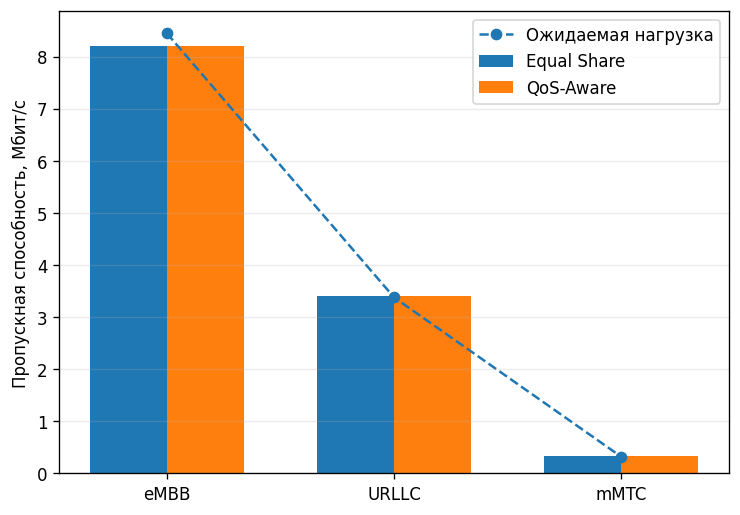

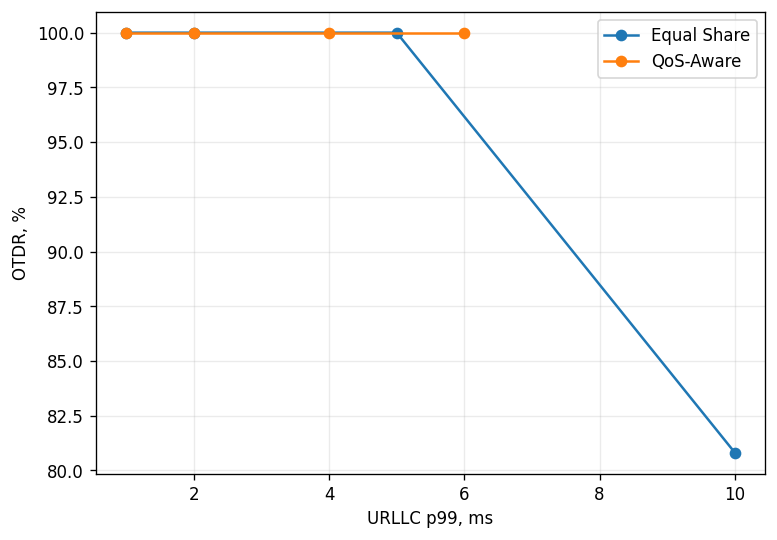

In [4]:
x=np.arange(3); w=.34
plt.figure(figsize=(7.2,5.0))
for j,pol in enumerate(('Equal Share','QoS-Aware')):
    g=comparison_df[comparison_df.policy==pol].set_index('service').loc[list(SERVICES)]
    plt.bar(x+(j-.5)*w,g.throughput_mbps,width=w,label=pol)
plt.plot(x,profile_df.set_index('service').loc[list(SERVICES)]['expected_offered_mbps'],marker='o',linestyle='--',label='Ожидаемая нагрузка')
plt.xticks(x,SERVICES); plt.ylabel('Пропускная способность, Мбит/с'); plt.legend(); plt.grid(axis='y',alpha=.25); plt.show()

load_df=load_sweep(v,(0.5,1.0,1.5,2.0))
plt.figure(figsize=(7.2,5.0))
for pol in ('Equal Share','QoS-Aware'):
    g=load_df[(load_df.policy==pol)&(load_df.service=='URLLC')].sort_values('load_multiplier')
    plt.plot(g.p99_delay_ms,100*g.on_time_delivery_ratio,marker='o',label=pol)
plt.xlabel('URLLC p99, ms'); plt.ylabel('OTDR, %'); plt.legend(); plt.grid(alpha=.25); plt.show()

## 5. Sensitivity по нагрузке и capacity

 load_multiplier      policy service  throughput_mbps  p99_delay_ms  deadline_miss_ratio  on_time_delivery_ratio  delivery_ratio_eval  qos_score  overall_qos_score  worst_service_qos_score
             0.5 Equal Share    eMBB           4.0781          4.00               0.0000                  1.0000               1.0000     0.9998             0.9999                   0.9998
             0.5 Equal Share   URLLC           1.6986          1.00               0.0000                  1.0000               1.0000     1.0000             0.9999                   0.9998
             0.5 Equal Share    mMTC           0.1690          1.00               0.0000                  1.0000               1.0000     1.0000             0.9999                   0.9998
             0.5   QoS-Aware    eMBB           4.0781          4.00               0.0000                  1.0000               1.0000     0.9998             0.9999                   0.9998
             0.5   QoS-Aware   URLLC           1.6986  

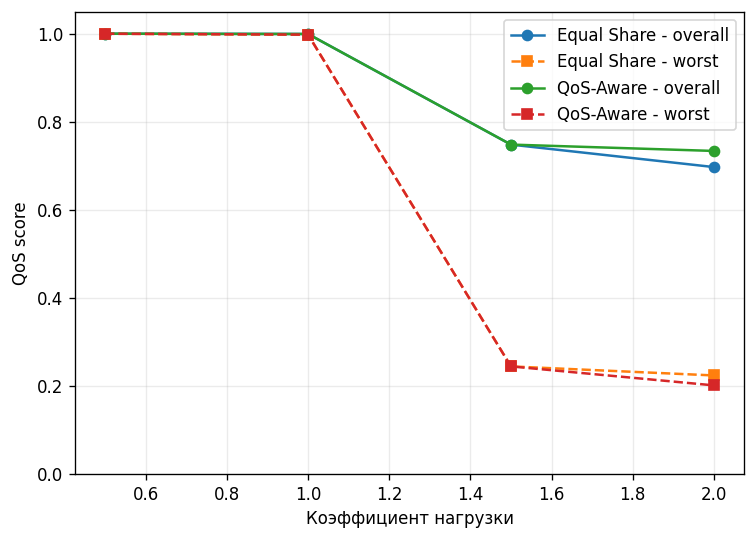

In [5]:
capacity_df=capacity_sensitivity(v,(0.75,1.0,1.25,1.5))
display(load_df[['load_multiplier','policy','service','throughput_mbps','p99_delay_ms','deadline_miss_ratio','on_time_delivery_ratio','delivery_ratio_eval','qos_score','overall_qos_score','worst_service_qos_score']].round(4))
display(capacity_df[['capacity_multiplier','capacity_mbps','policy','service','throughput_mbps','p99_delay_ms','deadline_miss_ratio','on_time_delivery_ratio','qos_score','overall_qos_score','worst_service_qos_score']].round(4))
plt.figure(figsize=(7.2,5.0))
for pol in ('Equal Share','QoS-Aware'):
    g=load_df[load_df.policy==pol].groupby('load_multiplier',as_index=False).agg(overall=('overall_qos_score','first'),worst=('worst_service_qos_score','first')).sort_values('load_multiplier')
    plt.plot(g.load_multiplier,g.overall,marker='o',label=f'{pol} - overall')
    plt.plot(g.load_multiplier,g.worst,marker='s',linestyle='--',label=f'{pol} - worst')
plt.xlabel('Коэффициент нагрузки'); plt.ylabel('QoS score'); plt.ylim(0,1.05); plt.legend(); plt.grid(alpha=.25); plt.show()

## 6. Multi-seed Monte Carlo и 95% CI

In [6]:
mc_df=monte_carlo_summary(v,n_runs=5,load_multiplier=2.0)
display(mc_df.round(5))
for pol in ('Equal Share','QoS-Aware'):
    out=simulate(v,pol,load_multiplier=2.0)
    m=teaching_sla_matrix(out['summary']); m.insert(0,'policy',pol)
    display(m.round(5))

     policy  n_runs  load_multiplier  embb_throughput_mean  embb_throughput_ci95  urllc_p99_mean  urllc_p99_ci95  urllc_otdr_mean  urllc_otdr_ci95  mmtc_pdr_mean  mmtc_pdr_ci95  overall_qos_mean  overall_qos_ci95  worst_service_qos_mean  worst_service_qos_ci95
Equal Share       5              2.0               5.68051               0.00328            10.0             0.0          0.80424          0.00351            1.0            0.0           0.69592           0.00086                 0.22322                 0.00022
  QoS-Aware       5              2.0               4.59341               0.02914             6.0             0.0          1.00000          0.00000            1.0            0.0           0.73314           0.00040                 0.19964                 0.00123
     policy service                       criterion    value  target   met
Equal Share    eMBB Throughput satisfaction >= 0.95  0.33867   0.950 False
Equal Share    eMBB         Delay violation <= 0.05  0.33423   0.05

## 7. Сохранение и sanity-checks

In [7]:
prefix=f'A6v2_variant_{VARIANT:02d}'
profile_df.to_csv(prefix+'_service_profiles.csv',index=False)
comparison_df.to_csv(prefix+'_qos_kpi.csv',index=False)
load_df.to_csv(prefix+'_load_sweep.csv',index=False)
capacity_df.to_csv(prefix+'_capacity_sensitivity.csv',index=False)
mc_df.to_csv(prefix+'_monte_carlo_ci.csv',index=False)
tr=[]
for pol,o in outputs.items():
    q=o['queue_trace'].copy(); q.insert(0,'policy',pol); tr.append(q)
queue_df=pd.concat(tr,ignore_index=True); queue_df.to_csv(prefix+'_queue_trace.csv',index=False)
for pol,o in outputs.items():
    s=o['summary']
    assert ((s.generated_packets==s.delivered_packets+s.dropped_packets+s.pending_packets)).all()
    assert ((s.eval_packets==s.eval_delivered_packets+s.eval_dropped_packets+s.eval_pending_packets)).all()
    assert ((s.qos_score>=0)&(s.qos_score<=1)).all()
    assert (s.radio_error_ratio==0).all()
print('OK')

OK


## 8. Вывод студента
В 6–8 предложениях интерпретируйте eMBB throughput, URLLC p99/OTDR/DMR, mMTC PDR, decomposition потерь, worst-service QoS и 95% CI.